### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [17]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


In [18]:
print("dim de x", X.shape)
print("dim de y", y.shape)

dim de x torch.Size([300, 2])
dim de y torch.Size([300, 1])


In [19]:
salaire_moyen = y.mean()
print(f"Salaire moyen : {salaire_moyen:.2f} DH")

Salaire moyen : 15010.55 DH


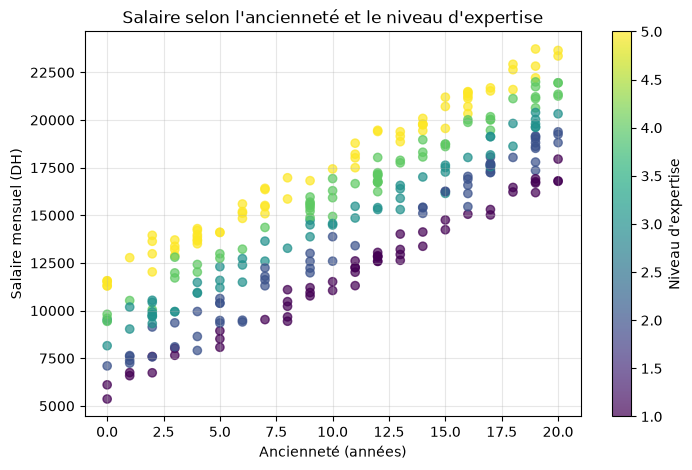

In [20]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X[:, 0],
    y[:, 0],
    c=X[:, 1],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(scatter, label="Niveau d'expertise")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et le niveau d'expertise")
plt.grid(True, alpha=0.3)

plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [21]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [27]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(100):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 10 | Perte : 38.3277
Époque 20 | Perte : 4.9617
Époque 30 | Perte : 0.8288
Époque 40 | Perte : 0.3135
Époque 50 | Perte : 0.2486
Époque 60 | Perte : 0.2404
Époque 70 | Perte : 0.2393
Époque 80 | Perte : 0.2392
Époque 90 | Perte : 0.2391
Époque 100 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


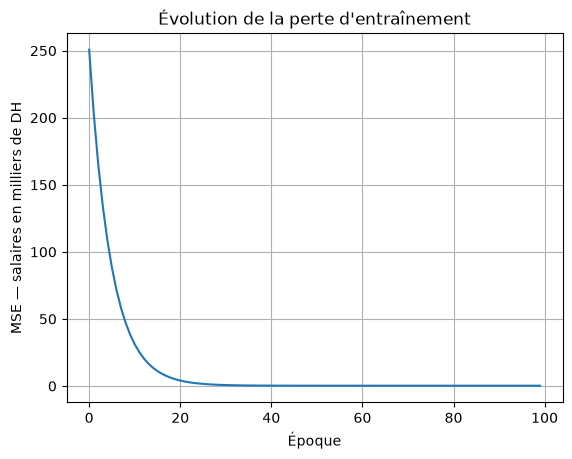

In [28]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [29]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # À compléter
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.75 DH


Interprétation : une MAE de 381.75 DH signifie que les prédictions s’écartent, en moyenne, de 381.75 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [30]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14201.54 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?

-> L'effet d'une année d'ancienneté devrait être proche de :
+600 DH par année, à expertise constante.


- Pourquoi la perte ne devient-elle pas exactement nulle ?

-> Le modèle ne connaît que l'ancienneté et l'expertise. Il ne peut donc pas prédire le bruit individuel.
C'est pour cela que la perte reste autour de 0.2391 au lieu d'arriver à 0.


- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?

-> les données d'entraînement contiennent uniquement une ancienneté entre 0 et 20 ans, le modèle est donc beaucoup plus fiable dans la plage 0–20 ans que pour 40 ans.


- Quel effet aurait une augmentation du bruit sur la précision ?

-> Le modèle aura plus de difficulté à retrouver le salaire exact, et la perte de test devrait augmenter.


- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [31]:
# Paramètres appris dans l'espace normalisé
w_norm = model.weight.detach().squeeze()
b_norm = model.bias.detach().item()

# Écart-type et moyenne des variables originales
sigma = ecart_type.squeeze()
mu = moyenne.squeeze()

# Conversion vers les unités originales
w_original = (w_norm / sigma) * 1000

b_original = (
    b_norm
    - torch.sum(w_norm * mu / sigma)
) * 1000

print("Coefficients en unités d'origine :")
print(f"Ancienneté : {w_original[0].item():.2f} DH/an")
print(f"Expertise  : {w_original[1].item():.2f} DH/niveau")
print(f"Constante  : {b_original.item():.2f} DH")

Coefficients en unités d'origine :
Ancienneté : 592.61 DH/an
Expertise  : 1490.53 DH/niveau
Constante  : 4091.14 DH


### Exercice 2: Classification


**1. Préparation des données**

In [36]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?

-> Longueur du sépale, Largeur du sépale, Longueur du pétale, Largeur du pétale


- Pourquoi utilise-t-on torch.long pour les étiquettes ?

-> On utilise torch.long car la fonction de perte nn.CrossEntropyLoss(), couramment utilisée pour la classification multiclasse, attend des étiquettes sous forme d'entiers (torch.long).


- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

-> Si on ajuste le scaler sur les données de test, on introduit une fuite de données (data leakage) : le prétraitement utilise des informations provenant du jeu de test.
Le jeu de test doit simuler des données nouvelles, jamais utilisées pendant l'apprentissage. Cela permet d'évaluer plus honnêtement la capacité du modèle à généraliser.

**2. Construire le réseau**

In [37]:
model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [ ]:
epochs = 200
losses = []

model.train()


for epoch in range(epochs):
    # TODO : remettre les gradients à zéro
    optimizer.zero_grad()

    # TODO : calculer les scores prédits
    logits = model(X_train)

    # TODO : calculer la perte
    loss = criterion(logits, y_train)       

    # TODO : calculer les gradients
    loss.backward()

    # TODO : mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.5260
Époque  40 | Perte : 0.2794
Époque  60 | Perte : 0.1530
Époque  80 | Perte : 0.0960
Époque 100 | Perte : 0.0714
Époque 120 | Perte : 0.0595
Époque 140 | Perte : 0.0524
Époque 160 | Perte : 0.0475
Époque 180 | Perte : 0.0439
Époque 200 | Perte : 0.0413


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [39]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # TODO : sélectionner la classe au score maximal pour chaque fleur
    predictions = torch.argmax(logits, dim=1)

    # TODO : calculer la proportion de prédictions correctes
    accuracy = torch.mean((predictions == y_test).float())

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 96.7%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

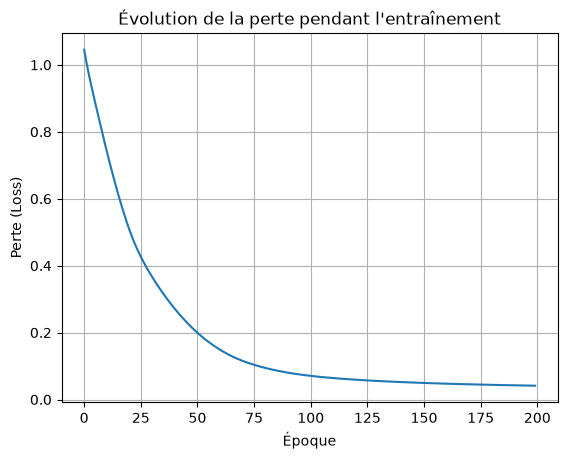

In [40]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (Loss)")
plt.title("Évolution de la perte pendant l'entraînement")
plt.grid(True)
plt.show()

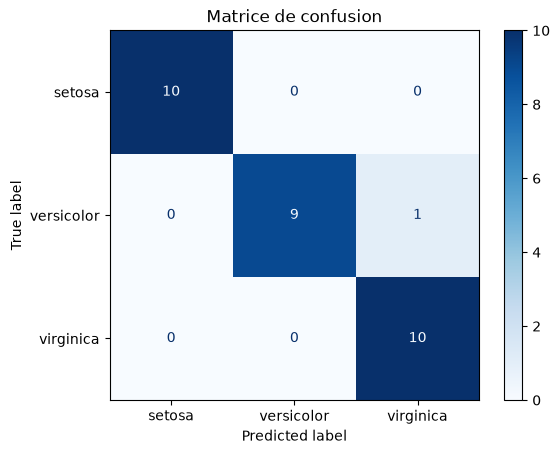

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
# 2. Matrice de confusion
cm = confusion_matrix(y_test.numpy(), predictions.numpy())

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion")
plt.show()

In [44]:
# 3. Comparaison avec un modèle sans couche cachée
model_simple = nn.Linear(4, 3)

criterion_simple = nn.CrossEntropyLoss()
optimizer_simple = torch.optim.SGD(
    model_simple.parameters(), lr=0.05
)

for epoch in range(200):
    optimizer_simple.zero_grad()
    sorties_simple = model_simple(X_train)
    loss_simple = criterion_simple(sorties_simple, y_train)
    loss_simple.backward()
    optimizer_simple.step()

model_simple.eval()

with torch.no_grad():
    pred_simple = model_simple(X_test).argmax(dim=1)

accuracy_simple = accuracy_score(
    y_test.numpy(), pred_simple.numpy()
)

print(f"Réseau avec couche cachée : {accuracy:.2%}")
print(f"Modèle linéaire simple    : {accuracy_simple:.2%}")


Réseau avec couche cachée : 96.67%
Modèle linéaire simple    : 83.33%


In [45]:
# 4. Prédiction d'une nouvelle fleur
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]

# Utiliser le même scaler ajusté sur X_train
fleur_normalisee = scaler.transform(nouvelle_fleur)
fleur_tensor = torch.tensor(
    fleur_normalisee, dtype=torch.float32
)

with torch.no_grad():
    sortie = model(fleur_tensor)
    classe = sortie.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])

Espèce prédite : setosa


### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [46]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

100.0%
100.0%
100.0%
100.0%


#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

In [47]:
for epoch in range(5):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        # Réinitialiser les gradients
        optimizer.zero_grad()

        # Prédictions
        outputs = model(images)

        # Calcul de la perte
        loss = criterion(outputs, labels)

        # Rétropropagation
        loss.backward()

        # Mise à jour des paramètres
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Époque {epoch + 1}/5 | "
        f"Perte : {total_loss / len(train_loader):.4f}"
    )

Époque 1/5 | Perte : 0.3463
Époque 2/5 | Perte : 0.1586
Époque 3/5 | Perte : 0.1089
Époque 4/5 | Perte : 0.0816
Époque 5/5 | Perte : 0.0649


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_labels = []
all_images = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)

        predicted_classes = outputs.argmax(dim=1)

        all_predictions.extend(predicted_classes.tolist())
        all_labels.extend(labels.tolist())
        all_images.extend(images)

# Calcul des métriques
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9736
Precision : 0.9736
Recall    : 0.9734
F1-Score  : 0.9734


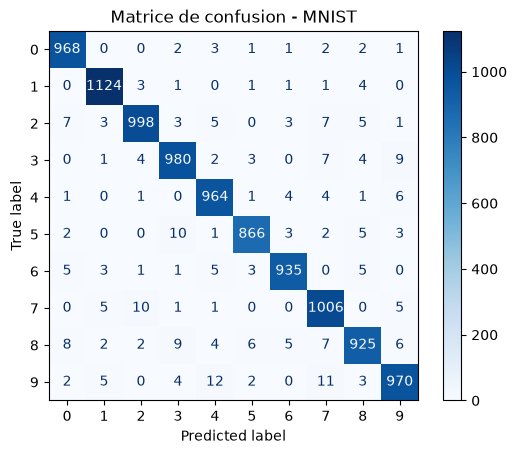

In [49]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - MNIST")
plt.show()

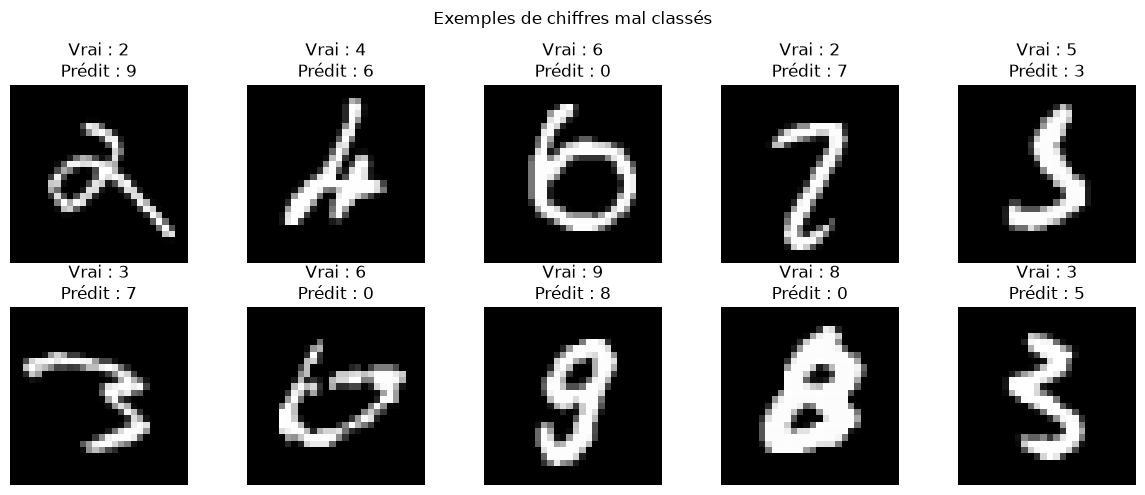

In [50]:
# Indices des prédictions incorrectes
erreurs = [
    i for i in range(len(all_labels))
    if all_labels[i] != all_predictions[i]
]

# Afficher jusqu'à 10 erreurs
nb_images = min(10, len(erreurs))

plt.figure(figsize=(12, 5))

for j, idx in enumerate(erreurs[:nb_images]):
    plt.subplot(2, 5, j + 1)

    plt.imshow(all_images[idx].squeeze(), cmap="gray")
    plt.title(
        f"Vrai : {all_labels[idx]}\n"
        f"Prédit : {all_predictions[idx]}"
    )
    plt.axis("off")

plt.suptitle("Exemples de chiffres mal classés")
plt.tight_layout()
plt.show()

In [51]:
torch.save(model.state_dict(), "mnist_model.pth")

In [52]:
# Recréer la même architecture
model_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

# Charger les paramètres sauvegardés
model_recharge.load_state_dict(
    torch.load("mnist_model.pth", map_location="cpu", weights_only=True)
)

model_recharge.eval()

print("Modèle rechargé avec succès.")

Modèle rechargé avec succès.
